# Proyecto 3: Histograma de Temperaturas y MergeSort con CUDA

**Universidad del Valle de Guatemala**  
**CC3069 - Computación Paralela y Distribuida** — Semestre II, 2026  
**Equipo:**  
- Marinés García (23391)  
- Camila Richter (23183)  
- Carlos Alburez (231311)  

---  
### Resumen de la solución
Este proyecto optimiza y acelera el algoritmo de la **Evaluación Corta 2** (MergeSort + Histograma de 100 cubetas) mediante una arquitectura híbrida CPU-GPU:
1. **Fase CPU multinúcleo (`multiprocessing`):**  
   - F1: Generación determinista de temperaturas por bloques con semillas independientes.  
   - F6: Formateo y escritura paralela a disco de `temperaturas_ordenadas.csv`, `histograma.dat` e `histograma.png`.
2. **Fase GPU masiva (`Numba CUDA`):**  
   - F2/F5: Transferencias Host $\leftrightarrow$ Device a través de PCIe.  
   - F3: **MergeSort bottom-up iterativo**, alternando buffers en VRAM sin transferencias intermedias.  
   - F4: **Histograma con memoria compartida (Shared Memory)** y sumas atómicas locales por bloque.

## 1. Verificación del Entorno y GPU
Se comprueba la disponibilidad de la GPU NVIDIA (T4 en Google Colab) y la compatibilidad con CUDA.

In [16]:
# Clonar y entrar al repositorio en Google Colab si aún no estamos dentro
import os
if not os.path.exists("comun"):
    !git clone https://github.com/NESHGP04/proyecto3-PL.git
    %cd proyecto3-PL

!nvidia-smi

Mon Nov 16 22:34:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P0             26W /   70W |     107MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [17]:
from numba import cuda
print("Dispositivo CUDA detectado:")
cuda.detect()

Dispositivo CUDA detectado:
Found 1 CUDA devices
id 0                Tesla T4                              [SUPPORTED]
                      Compute Capability: 7.5
                           PCI Device ID: 4
                              PCI Bus ID: 0
                                    UUID: GPU-2bafd2d4-243e-31f5-381d-2fd98ce4d264
                                Watchdog: Disabled
             FP32/FP64 Performance Ratio: 32
                            FP16 Support: Yes
                            BF16 Support: No
                             FP8 Support: No
Summary:
	1/1 devices are supported


True

## 2. Instalación de Dependencias e Importaciones

In [18]:
!pip install -q -r requirements.txt

import os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

from comun.config import TAMANOS, CUBETAS, FASES
from comun.datos import generar_secuencial
import secuencial.histograma_seq as seq
import paralelo.histograma_cuda as cuda_pipe

## 3. Pruebas de Validación y Corrección Algorítmica
Antes de medir rendimiento, se valida obligatoriamente que:
- El arreglo ordenado por la GPU sea idéntico a `np.sort`.
- El histograma de la GPU coincida exactamente con la versión secuencial de referencia.
- La suma total de frecuencias en las 100 cubetas sea estrictamente igual a $N$.

In [19]:
# Validación con N = 100,000 elementos
cuda_pipe.validar(100_000)

Iniciando validación con N = 100,000...
 Validación exitosa para N = 100,000:
   - Ordenamiento GPU coincide con np.sort
   - Histograma GPU coincide con secuencial (100 cubetas)
   - Suma total de frecuencias = 100,000


True

## 4. Ejecución del Pipeline Paralelo con Monitoreo de Recursos
Se ejecuta una corrida de demostración con $N = 1,000,000$ registrando el uso de recursos de hardware en segundo plano.

In [20]:
from benchmarks.monitor_recursos import MonitorCPU, guardar_estado_gpu

guardar_estado_gpu("evidencias/nvidia_smi_antes.txt")

print("Corriendo pipeline paralelo con N = 1,000,000 y monitoreo de CPU activo...")
with MonitorCPU("evidencias/cpu_por_nucleo.csv", intervalo=0.2):
    ordenado, hist, tiempos = cuda_pipe.ejecutar(1_000_000, escribir_archivos=True, carpeta_salida="resultados/demo")

guardar_estado_gpu("evidencias/nvidia_smi_durante.txt")

print("\n--- Desglose de tiempos de la versión CUDA (N = 1,000,000) ---")
for fase in FASES:
    print(f"{fase:<15}: {tiempos[fase]:.5f} s")

Estado de GPU guardado en evidencias/nvidia_smi_antes.txt
Corriendo pipeline paralelo con N = 1,000,000 y monitoreo de CPU activo...
Estado de GPU guardado en evidencias/nvidia_smi_durante.txt

--- Desglose de tiempos de la versión CUDA (N = 1,000,000) ---
preparacion    : 0.07411 s
h2d            : 0.00200 s
ordenamiento   : 0.40185 s
histograma     : 0.00094 s
d2h            : 0.00243 s
escritura      : 1.58731 s
total          : 2.07214 s


## 5. Benchmarks Oficiales (10 repeticiones por tamaño)
Se ejecuta la suite completa de benchmarks para $N = 10^4, 10^5, 10^6$ (descartando la primera corrida como calentamiento JIT).

In [21]:
!python -m benchmarks.run_benchmarks --modo cuda

Benchmark modo cuda: N = [10000, 100000, 1000000], 10 repeticiones

/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 20 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 10 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 5 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 3 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/pyt

Se generan las tablas comparativas, métricas de speedup por fase y gráficas oficiales:

In [22]:
!python -m benchmarks.run_benchmarks --modo graficas

Resumen guardado en resultados/resumen_secuencial.csv
Figuras de la versión secuencial guardadas en informe/figuras/
Tabla para el informe guardada en resultados/tabla_secuencial.md
Speedup guardado en resultados/speedup.csv y resultados/tabla_comparativa.md
Figuras de comparación guardadas en informe/figuras/
  N =     10,000: speedup total 0.70×  (límite de Amdahl 0.72×)
  N =    100,000: speedup total 1.49×  (límite de Amdahl 1.72×)
  N =  1,000,000: speedup total 4.52×  (límite de Amdahl 5.70×)


## 6. Resultados y Visualización de Gráficas de Speedup


Mostrando informe/figuras/comparativa_total.png:


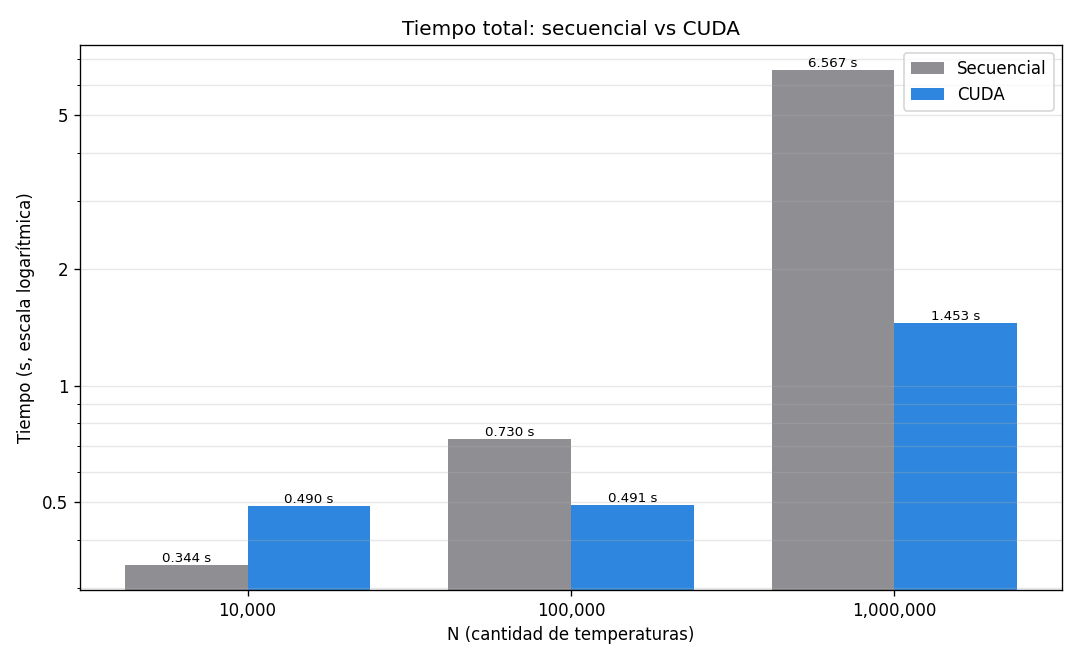


Mostrando informe/figuras/speedup_por_fase.png:


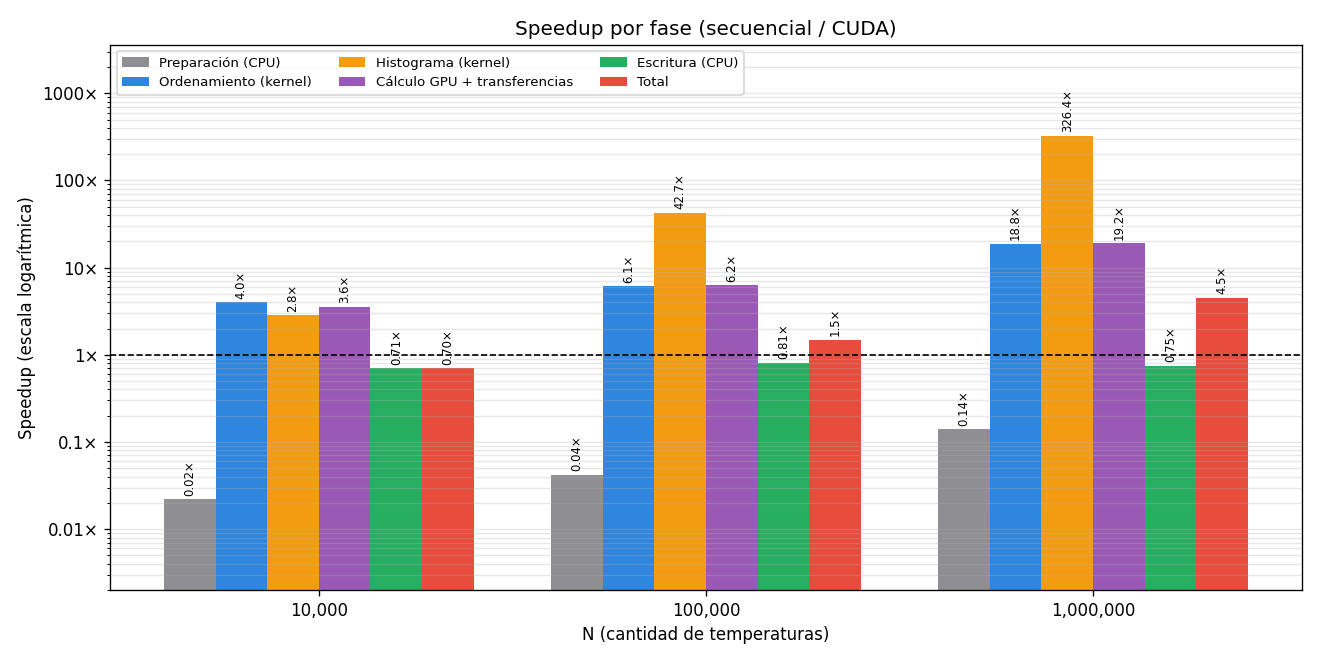


Mostrando informe/figuras/cuda_porcentaje_por_fase.png:


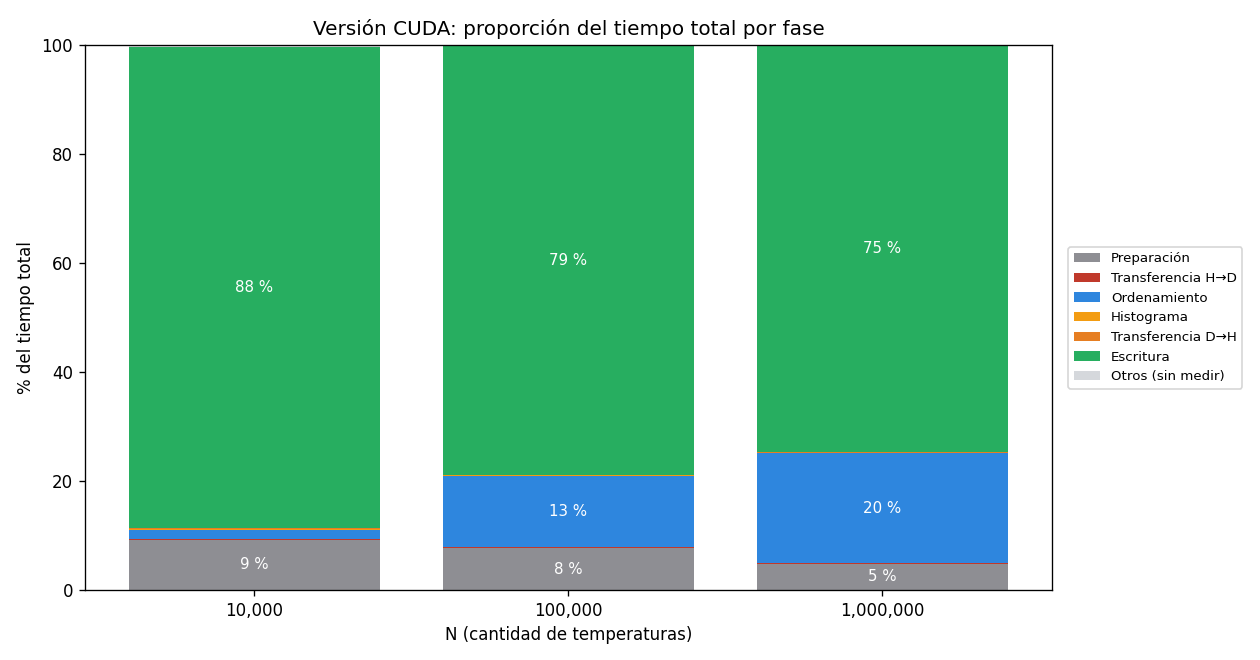

In [23]:
figuras = [
    "informe/figuras/comparativa_total.png",
    "informe/figuras/speedup_por_fase.png",
    "informe/figuras/cuda_porcentaje_por_fase.png"
]

for ruta in figuras:
    if os.path.exists(ruta):
        print(f"\nMostrando {ruta}:")
        display(Image(filename=ruta))
    else:
        print(f"Gráfica {ruta} aún no generada (ejecutar benchmarks primero).")

## 7. Tabla Comparativa de Rendimiento y Speedup

In [24]:
tabla_md = "resultados/tabla_comparativa.md"
if os.path.exists(tabla_md):
    with open(tabla_md, "r", encoding="utf-8") as f:
        print(f.read())
else:
    print("Tabla comparativa no encontrada. Asegúrese de correr --modo graficas con ambos resultados.")

**N = 10,000**

| Fase | Secuencial (s) | CUDA (s) | Speedup |
|---|---|---|---|
| Preparación (CPU) | 0.0010 | 0.0452 | 0.02× |
| Ordenamiento (kernel) | 0.0344 | 0.0085 | 4.04× |
| Histograma (kernel) | 0.0023 | 0.0008 | 2.85× |
| Cálculo GPU + transferencias | 0.0367 | 0.0103 | 3.55× |
| Escritura (CPU) | 0.3059 | 0.4332 | 0.71× |
| **Total** | 0.3436 | 0.4903 | **0.70×** |
| *Límite de Amdahl (GPU en 0 s)* | 0.3436 | 0.4783 | *0.72×* |

**N = 100,000**

| Fase | Secuencial (s) | CUDA (s) | Speedup |
|---|---|---|---|
| Preparación (CPU) | 0.0016 | 0.0376 | 0.04× |
| Ordenamiento (kernel) | 0.3942 | 0.0648 | 6.08× |
| Histograma (kernel) | 0.0208 | 0.0005 | 42.66× |
| Cálculo GPU + transferencias | 0.4150 | 0.0665 | 6.24× |
| Escritura (CPU) | 0.3137 | 0.3862 | 0.81× |
| **Total** | 0.7303 | 0.4911 | **1.49×** |
| *Límite de Amdahl (GPU en 0 s)* | 0.7303 | 0.4238 | *1.72×* |

**N = 1,000,000**

| Fase | Secuencial (s) | CUDA (s) | Speedup |
|---|---|---|---|
| Preparación (CPU) | 0.

## 8. Compilación del Informe Final en HTML / PDF

In [25]:
!pip install -q markdown
!python informe/armar_informe.py

print("\nDescarga del informe compilado:")
try:
    from google.colab import files
    if os.path.exists("informe/Informe_Proyecto3.html"):
        files.download("informe/Informe_Proyecto3.html")
        print("Descargando informe/Informe_Proyecto3.html... Ábrelo en Chrome/Safari y presiona Imprimir -> Guardar como PDF.")
except ImportError:
    pass

Informe generado: informe/Informe_Proyecto3.html (1.3 MB)

⚠️  2 pendiente(s) antes de entregar:
   - 06_resultados.md: quedan 24 valores ⟨…⟩ por llenar
   - 06_discusion.md: quedan 20 valores ⟨…⟩ por llenar

Descarga del informe compilado:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descargando informe/Informe_Proyecto3.html... Ábrelo en Chrome/Safari y presiona Imprimir -> Guardar como PDF.
